# Stage 3 — Evaluation & Analysis

Đánh giá test bằng PhoBERT và baseline **đã chọn từ validation**. Không train hoặc tuning thêm.
Kết quả local có sẵn trong `outputs/stage3/`; chạy các ô đọc báo cáo để xem.
Nếu dùng Colab, upload bản dự án mới cùng artifact; mount Drive trước khi đặt `PROJECT`.
Không dùng test để chọn lại cấu hình. Softmax chưa được hiệu chuẩn.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
# Colab: mount Drive rồi dùng Path('/content/drive/MyDrive/ViToxic-Analyzer')
OUTPUT = PROJECT / 'outputs/stage3'
assert (PROJECT / 'src/evaluate.py').is_file(), 'Đặt PROJECT thành thư mục gốc dự án'


## Thực thi (chỉ khi chưa có kết quả)

Cài `requirements/stage2.txt` và Java trước khi chạy lần đầu. Baseline Colab được lưu bằng
scikit-learn 1.6.1; nên dùng phiên bản này khi tái lập. Pipeline kiểm tra lại điểm validation
của baseline, khóa model/data hashes, rồi mới inference test. CPU có thể mất vài phút.
Ô dưới mặc định chỉ đọc báo cáo đã có; đặt `RUN_EVALUATION = True` để thực thi nếu cần.

In [2]:
RUN_EVALUATION = False
if RUN_EVALUATION:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'src.evaluate'], cwd=PROJECT, check=True)
assert (OUTPUT / 'metrics.json').is_file(), 'Chưa có kết quả: chạy pipeline trước'


In [3]:
display(pd.read_csv(OUTPUT / 'comparison.csv'))
display(pd.read_csv(OUTPUT / 'phobert_classification_report.csv', index_col=0))

,model,macro_f1,weighted_f1,accuracy
0,baseline,0.632496,0.849376,0.843563
1,phobert,0.654565,0.866463,0.864671


,precision,recall,f1-score,support
CLEAN,0.935117,0.932588,0.933851,5548.000000
OFFENSIVE,0.378928,0.461712,0.416244,444.000000
HATE,0.655116,0.577035,0.613601,688.000000
accuracy,0.864671,0.864671,0.864671,0.864671
macro avg,0.656387,0.657112,0.654565,6680.000000
weighted avg,0.869310,0.864671,0.866463,6680.000000


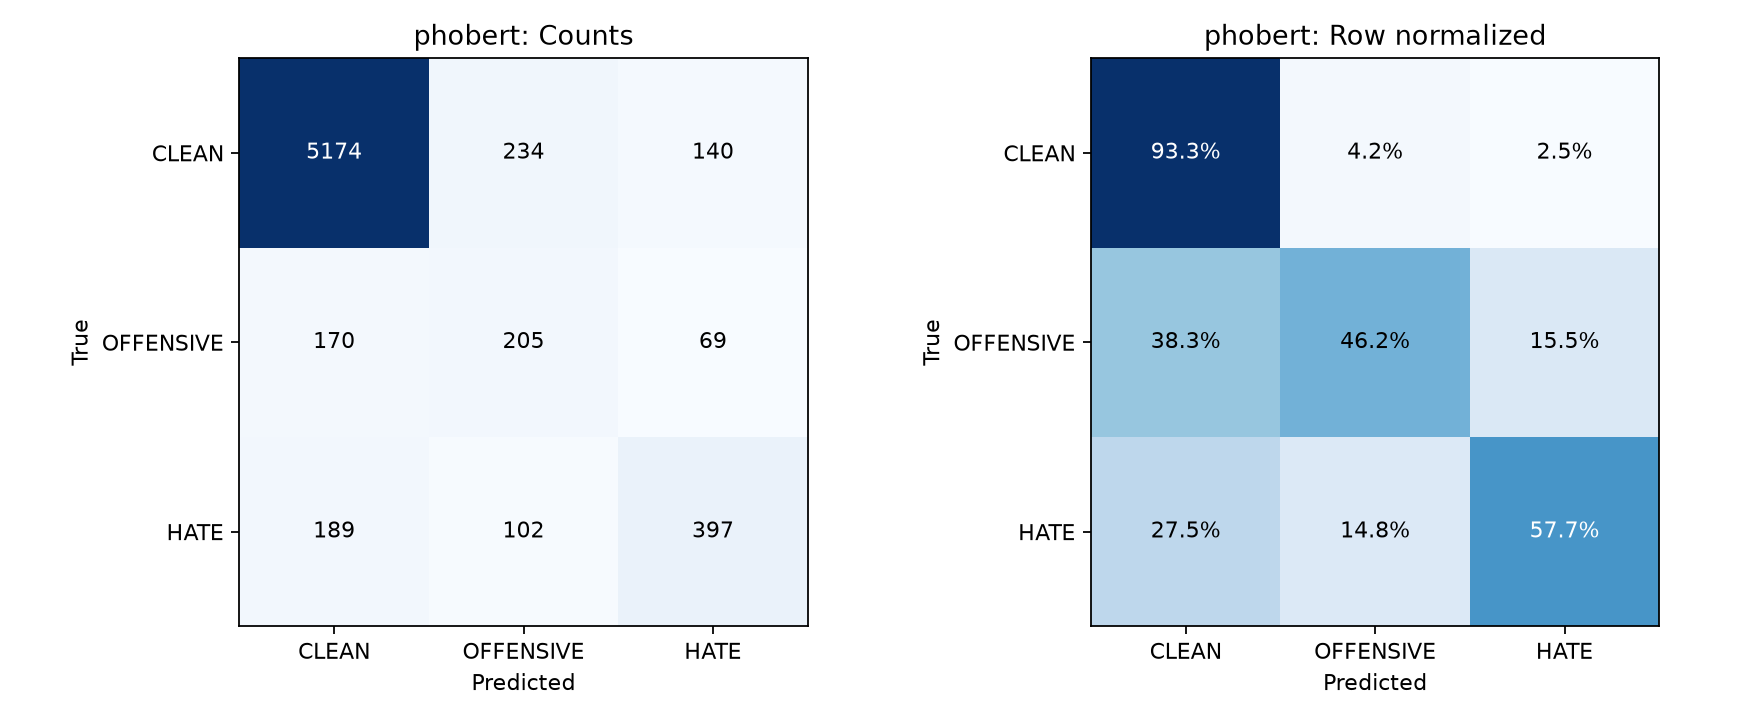

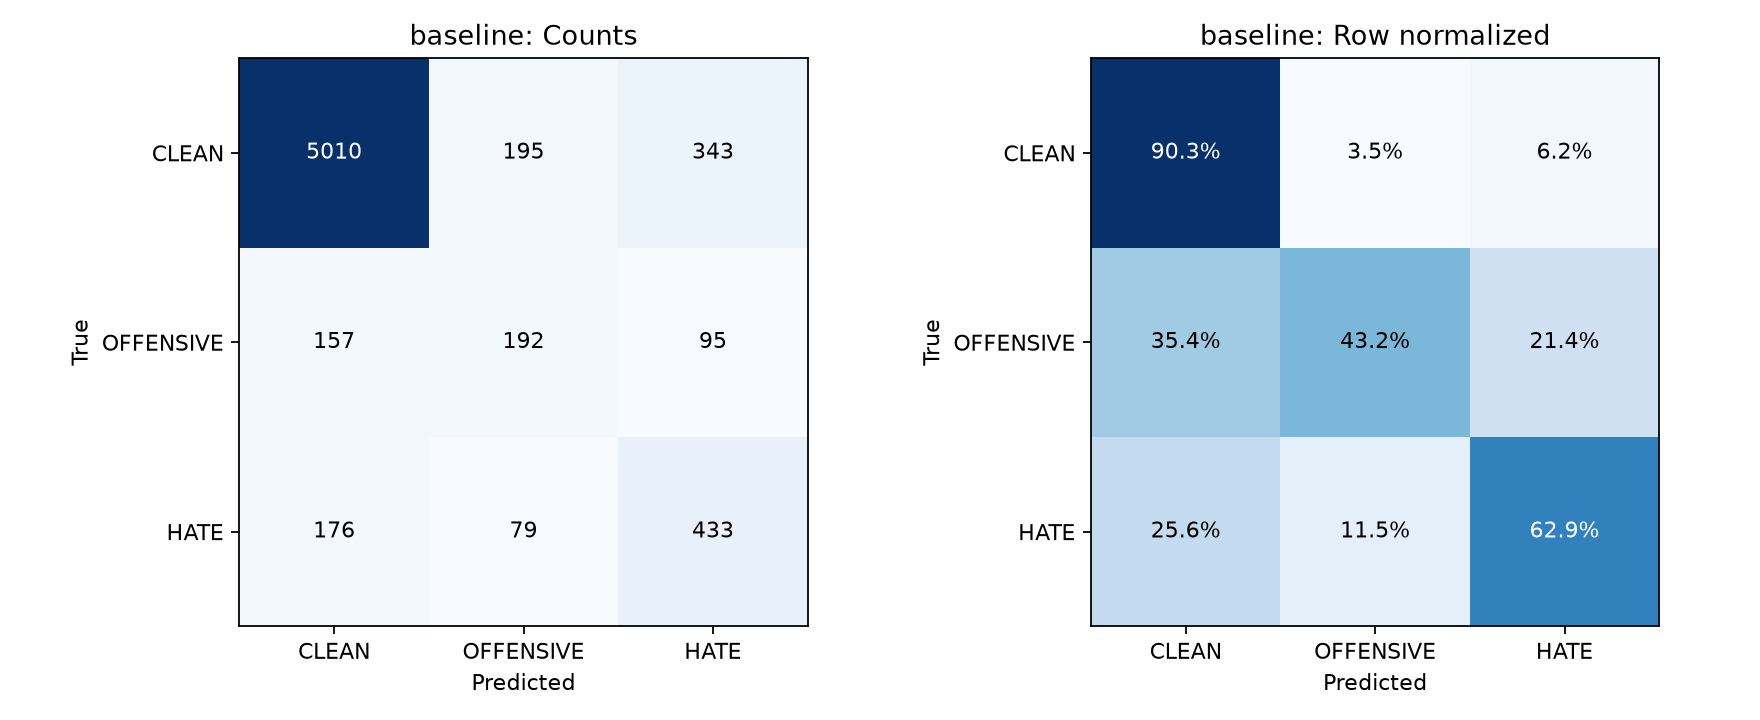

In [4]:
display(Image(filename=str(OUTPUT / 'phobert_confusion_matrix.png')))
display(Image(filename=str(OUTPUT / 'baseline_confusion_matrix.png')))

In [5]:
display(pd.read_csv(OUTPUT / 'slices.csv'))
display(json.loads((OUTPUT / 'bootstrap.json').read_text(encoding='utf-8')))

,slice,rows,errors,accuracy,macro_f1,weighted_f1
0,all,6680,904,0.864671,0.654565,0.866463
1,validation_overlap,95,8,0.915789,0.718713,0.913927
2,no_validation_overlap,6585,896,0.863933,0.653637,0.865792
3,tokens_0_32,6219,806,0.870397,0.645013,0.871680
4,tokens_33_128,458,97,0.788210,0.594887,0.787950
5,tokens_over_128,3,1,0.666667,0.555556,0.777778


{'repetitions': 2000,
 'seed': 42,
 'confidence': 0.95,
 'intervals': {'baseline': [0.6143418891476313, 0.6502164313093668],
  'phobert': [0.6359636033169934, 0.6728372935338658],
  'difference': [0.002595712817171478, 0.04180102913999858]}}

## Đọc lỗi theo ngữ cảnh

`errors.csv` giữ toàn bộ lỗi; `error_review.csv` chọn tối đa 10 lỗi confidence cao mỗi hướng nhầm.
Đây là mẫu chẩn đoán có thiên lệch chọn mẫu. Đọc văn bản và ghi nhận xét vào bản sao;
không tự sửa ground truth. Có thể ghi thiếu ngữ cảnh, cách viết/teencode, mỉa mai hoặc
ranh giới OFFENSIVE/HATE nếu có bằng chứng; không khẳng định nguyên nhân chỉ từ model.
Không có checkbox tự đánh giá nào được đánh dấu tự động.

In [6]:
display(pd.read_csv(OUTPUT / 'error_review.csv').head(20))

,row_id,text_clean,label_id,prediction,confidence,prob_clean,prob_offensive,prob_hate,token_length,validation_overlap,correct,baseline_prediction,review_category,review_notes
0,test:3821,Anh em yếu sly ib,1,0,0.998481,0.998481,0.000971,0.000548,7,False,False,0,NaN,NaN
1,test:3794,Manh thi song yeu thi chet,1,0,0.998465,0.998465,0.000943,0.000591,10,False,False,0,NaN,NaN
2,test:3327,"Vâng! Xin giới thiệu vs các bạn, đây là ông Ca...",2,0,0.998462,0.998462,0.000822,0.000715,17,False,False,0,NaN,NaN
3,test:6205,Top1 ca sĩ nhưng k biết hát :)),1,0,0.998458,0.998458,0.000858,0.000683,12,False,False,0,NaN,NaN
4,test:248,Nguc em hoi nho,1,0,0.998457,0.998457,0.001022,0.000521,7,False,False,0,NaN,NaN
5,test:3301,Huyền Khánh Phùng nếu e không tiện thì tôi sẽ ...,1,0,0.998453,0.998453,0.000916,0.000631,29,False,False,0,NaN,NaN
6,test:1501,Bọn dầy tớ chấp chi.,2,0,0.998447,0.998447,0.001004,0.000548,8,False,False,0,NaN,NaN
7,test:6659,Cám ơn đảng. Cám ơn nhà nc 😏,2,0,0.998435,0.998435,0.000922,0.000643,10,False,False,0,NaN,NaN
8,test:159,Like 10 năm chất Liek bằng đầu bùi,1,0,0.998433,0.998433,0.001036,0.000531,12,False,False,0,NaN,NaN
9,test:708,Hoàng Văn Thuận nên xử bắn hed,1,0,0.998409,0.998409,0.000901,0.000690,9,False,False,0,NaN,NaN


In [7]:
analysis = OUTPUT / 'qualitative_analysis.md'
if analysis.exists():
    display(Markdown(analysis.read_text(encoding='utf-8')))

# Phân tích lỗi theo ngữ cảnh

Phân tích do trợ lý thực hiện ngày 2026-10-13 từ `test_predictions.csv` và mẫu lỗi confidence cao
trong `error_review.csv`. Đây là nhận xét chẩn đoán, không phải nhãn nguyên nhân đã được chuyên gia
xác nhận. Không chỉnh sửa nhãn test và không điền hộ phần tự đánh giá của người học.

## Kết luận định lượng

- PhoBERT tăng **0,022069 Macro-F1** so với baseline, nhưng thấp hơn validation **0,029761**.
- OFFENSIVE là lớp khó nhất: precision 0,3789, recall 0,4617, F1 0,4162. Trong 444 mẫu,
  170 bị đoán CLEAN và 69 bị đoán HATE. Đồng thời 234 CLEAN và 102 HATE bị đoán OFFENSIVE.
- HATE: 397/688 mẫu đúng; 189 bị bỏ lọt thành CLEAN và 102 bị hạ xuống OFFENSIVE.
  Accuracy chung 86,47% che khuất một phần lỗi ở hai lớp ít mẫu hơn CLEAN.
  Baseline nhận đúng 433/688 HATE (recall 0,6294), cao hơn PhoBERT 0,5770: cải thiện
  Macro-F1/accuracy chung không đồng nghĩa tốt hơn trên mọi tiêu chí.
- Có 95 dòng test overlap với validation theo chuẩn hóa Stage 1. Bỏ nhóm này để phân tích
  độ nhạy cho Macro-F1 0,6536 trên 6.585 dòng, gần điểm chính 0,6546; điều này không loại trừ
  near-duplicates hoặc mọi dạng phụ thuộc giữa các tập.
- Chỉ 3/6.680 dòng vượt 128 token, trong đó 1 lỗi. Truncation không thể giải thích phần lớn
  904 lỗi trong lần chạy này. Nhóm 33–128 token có 97/458 lỗi, so với 806/6.219 ở nhóm ≤32;
  chưa thể quy kết quan hệ nhân quả vì phân bố nhãn và nội dung các nhóm khác nhau.

## Ví dụ cụ thể

| Row ID | Nhãn thật → dự đoán | Quan sát từ văn bản | Hướng kiểm tra |
|---|---|---|---|
| `test:6205` | OFFENSIVE → CLEAN | “Top1 ca sĩ nhưng k biết hát :))” thể hiện chê bai qua đối lập, viết tắt và emoticon; không cần từ tục để mang ý xúc phạm. | Khả năng nhận diện công kích gián tiếp/mỉa mai. Không đủ bằng chứng để khẳng định chính emoticon gây lỗi. |
| `test:1556` | OFFENSIVE → CLEAN | Kéo dài ký tự trong “chưaaa” và biến thể viết kéo dài của từ tục. | Độ bền với cách viết biến thể; chỉ thử chuẩn hóa/augmentation trên train và validation ở nghiên cứu sau. |
| `test:3327` | HATE → CLEAN | Câu giới thiệu có cụm “Cao Thất Đức”, có thể chứa chơi chữ/công kích một người. | Cần ngữ cảnh đối tượng và hướng dẫn nhãn để giải thích ranh giới HATE. Không tự suy ra nhãn sai. |
| `test:3960` | CLEAN → OFFENSIVE | “Sự lươn lẹo là vậy” được dữ liệu gán CLEAN dù có từ đánh giá tiêu cực. | Phân biệt đánh giá tiêu cực với xúc phạm trong ngữ cảnh; model có thể dựa quá nhiều vào từ tiêu cực, đây mới là giả thuyết. |
| `test:4257` | CLEAN → HATE | Câu dài vừa kể lại một clip vừa có các cụm đánh giá gay gắt. | Cần phân biệt trích dẫn/kể lại, nhận xét và công kích; nhãn CLEAN trong dữ liệu không tự động được coi là lỗi annotation. |
| `test:2856` | OFFENSIVE → HATE | Lời chê một “quan điểm” kèm từ tục. | Ranh giới mục tiêu bị công kích và mức độ xúc phạm; không đồng nhất có từ tục với HATE. |
| `test:6002` | HATE → OFFENSIVE | “Xạo l” rất ngắn, viết tắt, thiếu đối tượng trong câu. | Bổ sung ngữ cảnh hội thoại nếu nguồn dữ liệu cho phép; không đủ thông tin trong một câu để xác nhận nguyên nhân. |
| `test:5800` | HATE → OFFENSIVE | Có cách gọi miệt thị gắn với xu hướng tính dục. | Kiểm tra khả năng nhận diện công kích nhóm/đặc điểm cá nhân theo hướng dẫn gán nhãn. |

Các ví dụ được chọn có chủ đích để minh họa, không dùng để ước lượng tần suất từng nguyên nhân.
Chưa có double annotation hoặc đo agreement giữa người đánh giá.

## Đề xuất nghiên cứu tiếp theo

Ưu tiên xem lại hướng dẫn phân biệt OFFENSIVE/HATE và bổ sung ví dụ ngữ cảnh trên train/validation.
Khảo sát độ bền với không dấu, viết tắt và kéo dài ký tự bằng bộ đánh giá riêng; không sửa preprocessing
hiện tại rồi chọn phương án tốt nhất trên test này. Nếu cần triển khai, đo calibration và hành vi
abstain bằng validation/tập calibration; không dùng confidence softmax hiện có như xác suất đúng.
Mọi thay đổi sau khi đã xem test cần được công bố và đánh giá cuối trên holdout mới phù hợp.


# Stage 3 — Đánh giá test và phân tích lỗi

Model khóa từ validation: `phobert_lr3e-5_len128_drop01_batch16_seed42`. Test: 6,680 mẫu, seed huấn luyện 42.
Inference thực hiện local bằng checkpoint và baseline đã huấn luyện trên Colab; không fit lại.

| Model | Test Macro-F1 | Weighted-F1 | Accuracy |
|---|---:|---:|---:|
| baseline | 0.632496 | 0.849376 | 0.843563 |
| phobert | 0.654565 | 0.866463 | 0.864671 |

## Precision / recall / F1 theo lớp (PhoBERT)

| Lớp | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| CLEAN | 0.9351 | 0.9326 | 0.9339 | 5548 |
| OFFENSIVE | 0.3789 | 0.4617 | 0.4162 | 444 |
| HATE | 0.6551 | 0.5770 | 0.6136 | 688 |

## Phân tích lỗi

Tổng 904 dự đoán sai. Các hướng nhầm (nhãn thật → dự đoán):
- CLEAN → OFFENSIVE: 234 mẫu.
- HATE → CLEAN: 189 mẫu.
- OFFENSIVE → CLEAN: 170 mẫu.
- CLEAN → HATE: 140 mẫu.
- HATE → OFFENSIVE: 102 mẫu.
- OFFENSIVE → HATE: 69 mẫu.

Các lát cắt chẩn đoán (Macro-F1 luôn tính đủ ba lớp; lát cắt nhỏ cần thận trọng):

| Lát cắt | Số mẫu | Số sai | Macro-F1 |
|---|---:|---:|---:|
| all | 6680 | 904 | 0.6546 |
| validation_overlap | 95 | 8 | 0.7187 |
| no_validation_overlap | 6585 | 896 | 0.6536 |
| tokens_0_32 | 6219 | 806 | 0.6450 |
| tokens_33_128 | 458 | 97 | 0.5949 |
| tokens_over_128 | 3 | 1 | 0.5556 |

## Độ bất định và giới hạn

Paired bootstrap 2.000 lần, seed 42: CI 95% Macro-F1 PhoBERT [0.6359636033169934, 0.6728372935338658]; chênh lệch PhoBERT − baseline [0.002595712817171478, 0.04180102913999858].
Bootstrap theo dòng giả định mẫu độc lập; duplicate/ngữ cảnh chung có thể làm CI quá hẹp. Không đo biến thiên qua seed huấn luyện.
Test chính thức giữ nguyên; lát cắt bỏ overlap validation chỉ là phân tích độ nhạy, không thay điểm test chính.
Softmax confidence chưa được hiệu chuẩn. Không suy luận nguyên nhân ngôn ngữ hay nhãn sai chỉ từ confusion matrix.
`error_review.csv` chứa tối đa 10 lỗi confidence cao mỗi hướng nhầm, để người học xem ngữ cảnh và ghi nhận xét; không đại diện ngẫu nhiên cho toàn bộ lỗi.
Không sửa nhãn test, không chọn lại checkpoint/threshold/hyperparameters từ kết quả này. Chưa chứng minh chất lượng production.


## Đối chiếu quá trình học

Best epoch theo validation: 5; validation Macro-F1 0.684326, test Macro-F1 0.654565.
Train loss giảm từ 0.9219 xuống 0.3055; validation loss thấp nhất 0.8057, cuối cùng 1.6326.
Loss validation tăng trong khi train loss giảm là dấu hiệu overfitting; Macro-F1 vẫn tăng nên checkpoint epoch 5 đúng tiêu chí chọn đã khóa. Không đổi checkpoint sau khi xem test.


## Môi trường baseline

Baseline được serialize bằng scikit-learn 1.6.1 trên Colab; lần inference local dùng 1.9.1 và có cảnh báo khác phiên bản. C và validation Macro-F1 đã được kiểm tra lại trước test; không fit lại baseline. Nên dùng 1.6.1 khi tái lập môi trường gốc.

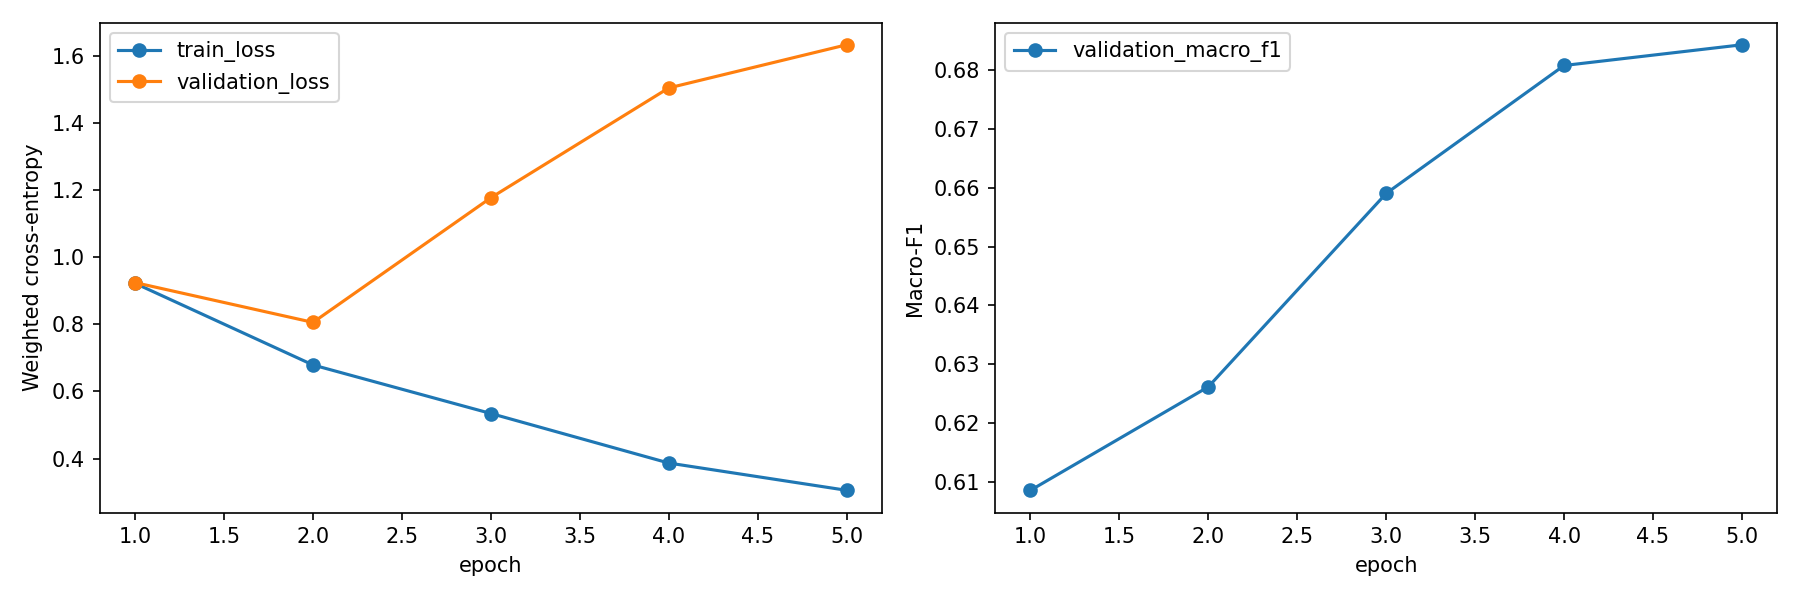

In [8]:
report = (OUTPUT / 'summary.md').read_text(encoding='utf-8')
display(Markdown('\n'.join(line for line in report.splitlines() if not line.startswith('!['))))
selected = json.loads((OUTPUT / 'lock.json').read_text(encoding='utf-8'))['selected_run']
display(Image(filename=str(PROJECT / 'outputs/stage2/runs' / selected / 'learning_curves.png')))